<a href="https://colab.research.google.com/github/JuanitaRozo/Resultados-de-tratamiento-de-imagen/blob/main/Informe_Tratamiento_Imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
#importacion de librerias
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Entorno de trabajo preparado correctamente.")


OpenCV: 5.0.0
NumPy: 2.1.3
Entorno de trabajo preparado correctamente.


In [18]:
#codigo para subir imagenes directamente desde el pc
from google.colab import files

archivos_subidos = files.upload()

print("\nArchivos recibidos:")
for nombre in archivos_subidos:
    print("-", nombre)


Saving IMG_1663.jpg to IMG_1663.jpg
Saving IMG_1664.jpg to IMG_1664.jpg
Saving IMG_1665.jpg to IMG_1665.jpg
Saving IMG_1666.jpg to IMG_1666.jpg
Saving IMG_1667.jpg to IMG_1667.jpg

Archivos recibidos:
- IMG_1663.jpg
- IMG_1664.jpg
- IMG_1665.jpg
- IMG_1666.jpg
- IMG_1667.jpg



Archivo: IMG_1663.jpg
Dimensiones (alto, ancho, canales): (4032, 3024, 3)


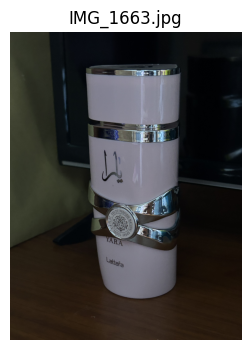


Archivo: IMG_1664.jpg
Dimensiones (alto, ancho, canales): (4032, 3024, 3)


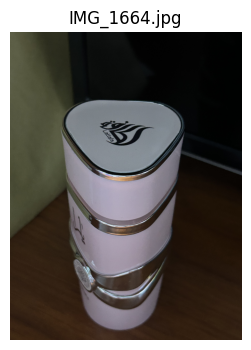


Archivo: IMG_1665.jpg
Dimensiones (alto, ancho, canales): (4032, 3024, 3)


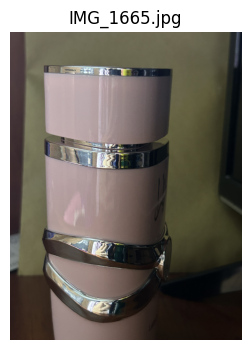


Archivo: IMG_1666.jpg
Dimensiones (alto, ancho, canales): (4032, 3024, 3)


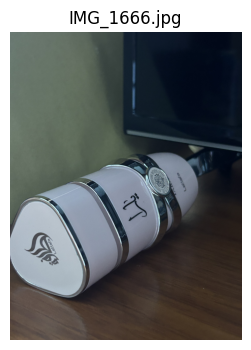


Archivo: IMG_1667.jpg
Dimensiones (alto, ancho, canales): (4032, 3024, 3)


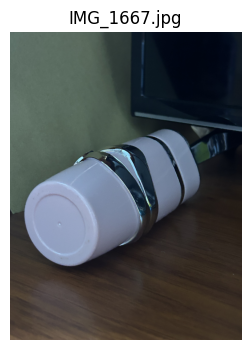


Total de imágenes válidas: 5


In [19]:
#revisar las imagenes subidas


from IPython.display import display

imagenes = {}

for nombre in archivos_subidos:
    imagen = cv2.imread(nombre)

    if imagen is None:
        print(f"No se pudo leer: {nombre}")
        continue

    imagenes[nombre] = imagen

    imagen_rgb = cv2.cvtColor(
        imagen, cv2.COLOR_BGR2RGB
    )

    print(f"\nArchivo: {nombre}")
    print("Dimensiones (alto, ancho, canales):", imagen.shape)

    plt.figure(figsize=(6, 4))
    plt.imshow(imagen_rgb)
    plt.title(nombre)
    plt.axis("off")
    plt.show()

print("\nTotal de imágenes válidas:", len(imagenes))


In [24]:
def calcular_metricas(imagen):
    gris = cv2.cvtColor(
        imagen, cv2.COLOR_BGR2GRAY
    )

    return {
        "Brillo": float(np.mean(gris)),
        "Contraste": float(np.std(gris)),
        "Nitidez": float(
            cv2.Laplacian(
                gris, cv2.CV_64F
            ).var()
        )
    }


registros = []

for nombre, imagen in imagenes.items():
    metricas = calcular_metricas(imagen)

    registros.append({
        "Imagen": nombre,
        **metricas
    })

tabla_metricas = pd.DataFrame(registros)

display(
    tabla_metricas.round(2)
)

tabla_metricas.to_csv(
    "metricas_originales.csv",
    index=False
)


,Imagen,Brillo,Contraste,Nitidez
0,IMG_1663.jpg,49.13,45.90,30.74
1,IMG_1664.jpg,58.81,51.94,13.00
2,IMG_1665.jpg,87.22,52.17,21.49
3,IMG_1666.jpg,76.85,51.47,20.62
4,IMG_1667.jpg,70.65,45.69,11.82


Imagen seleccionada: IMG_1663.jpg


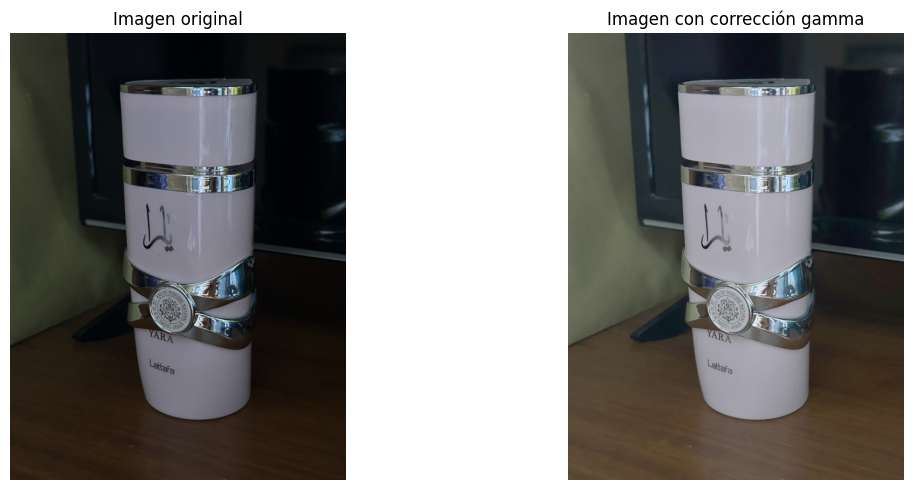

In [21]:
#aplicaremos el tratamiento de imagen

def corregir_gamma(imagen, gamma=0.60):
    normalizada = imagen.astype(
        np.float32
    ) / 255.0

    corregida = np.power(
        normalizada, gamma
    )

    return np.clip(
        corregida * 255.0, 0, 255
    ).astype(np.uint8)


# Seleccionar inicialmente la imagen con menor brillo.
# Después podremos cambiarla si el diagnóstico lo requiere.
nombre_problematica = min(
    imagenes,
    key=lambda nombre: calcular_metricas(
        imagenes[nombre]
    )["Brillo"]
)

original = imagenes[nombre_problematica]

procesada = corregir_gamma(
    original, gamma=0.60
)

print("Imagen seleccionada:", nombre_problematica)

original_rgb = cv2.cvtColor(
    original, cv2.COLOR_BGR2RGB
)

procesada_rgb = cv2.cvtColor(
    procesada, cv2.COLOR_BGR2RGB
)

fig, ejes = plt.subplots(
    1, 2, figsize=(13, 5)
)

ejes[0].imshow(original_rgb)
ejes[0].set_title("Imagen original")
ejes[0].axis("off")

ejes[1].imshow(procesada_rgb)
ejes[1].set_title("Imagen con corrección gamma")
ejes[1].axis("off")

plt.tight_layout()
plt.show()


,Estado,Brillo,Contraste,Nitidez
0,Antes del tratamiento,49.13,45.90,30.74
1,Después del tratamiento,84.56,51.15,36.68


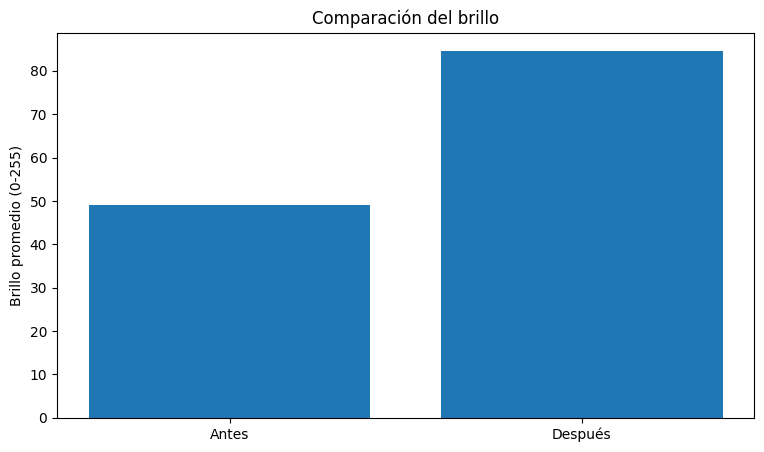

In [22]:
#comprobamos los resultados


metricas_antes = calcular_metricas(original)
metricas_despues = calcular_metricas(procesada)

comparacion = pd.DataFrame([
    {
        "Estado": "Antes del tratamiento",
        **metricas_antes
    },
    {
        "Estado": "Después del tratamiento",
        **metricas_despues
    }
])

display(comparacion.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    ["Antes", "Después"],
    [
        metricas_antes["Brillo"],
        metricas_despues["Brillo"]
    ]
)

plt.title("Comparación del brillo")
plt.ylabel("Brillo promedio (0-255)")
plt.show()


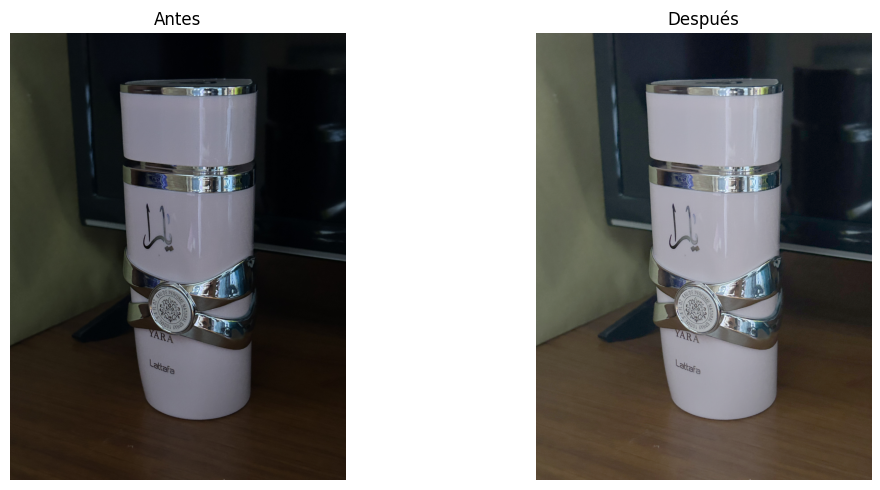

Resultados guardados correctamente.


In [23]:
#finalizamos guardando los resultados

from pathlib import Path

carpeta_resultados = Path("resultados")
carpeta_resultados.mkdir(exist_ok=True)

cv2.imwrite(
    str(carpeta_resultados / "imagen_original.jpg"),
    original
)

cv2.imwrite(
    str(carpeta_resultados / "imagen_corregida.jpg"),
    procesada
)

tabla_metricas.to_csv(
    carpeta_resultados / "metricas_originales.csv",
    index=False
)

comparacion.to_csv(
    carpeta_resultados / "comparacion_metricas.csv",
    index=False
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Antes")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(procesada_rgb)
plt.title("Después")
plt.axis("off")

plt.tight_layout()
plt.savefig(
    carpeta_resultados / "comparacion.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Resultados guardados correctamente.")
